# SPY: separate the archived pilot from a new market-data run

The public checkout contains **aggregate historical findings**, not observed option contracts, stock quotes, dividend records or vendor archives. Running this notebook audits optional input presence and displays the curated pilot derivative. It does not acquire data or refit a real surface.

The local pilot performed 31 fits, including synthetic controls and dated SPY call studies. Those records remain archived evidence; current live recomputation is explicitly not performed here. [Full public aggregate explanation](../reports/spy_pilot.md).

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/rvlab/pricing").is_dir())
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))
import rvlab
assert Path(rvlab.__file__).resolve().is_relative_to((ROOT / "src").resolve())
import numpy as np
import pandas as pd
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import public_notebook_support as demo
demo.style()
SEED = 42

Matplotlib is building the font cache; this may take a moment.


## 1. Audit optional inputs without inventing replacements

A new calibration needs independently observed stock prices, American-labelled option quotes, maturity-matched discount inputs and historically available expected dividend coverage. Presence alone does not establish availability, timestamp alignment, licensing or source independence. Set `RVLAB_SPY_DATA_ROOT` locally to a prepared data directory if available. Credentials and private files do not belong in the notebook or repository.

Missing files yield an honest not-recomputed state. No parity-derived forward, hypothetical spot, trailing dividend yield or synthetic market substitute is created.

In [2]:
input_status = demo.market_input_status()
display(input_status)
display(Markdown("**Live SPY calibration: not recomputed.** Optional inputs are absent or their availability has not been validated by this notebook. This checkout does not establish calibration or hedging readiness."))

,input,present,availability_verified,live_calibration_executed
0,independent stock,False,False,False
1,dated discount inputs,False,False,False
2,dated dividend expectations,False,False,False
3,prepared option sessions,False,False,False


**Live SPY calibration: not recomputed.** Optional inputs are absent or their availability has not been validated by this notebook. This checkout does not establish calibration or hedging readiness.

## 2. Understand the archived American-call assumptions

The archived pilot used calls with explicit empty expected-dividend coverage, nonnegative deterministic forward rates and the frictionless true-martingale model. Its forward was derived from independent spot and discounting, not European parity. An archived dividend calendar was accepted **conditionally on no subsequent notice**. Treasury yields were discount proxies, and interval-end observations were reconstructed snapshots rather than executable quotes.

Repeat stock acquisition passed its local gate, but independent intraday cross-source agreement was unavailable. The pilot therefore does not establish an independently validated market tape, historical rough conditioning, stock deltas, put pricing or hedging readiness.

## 3. Read aggregate fitting outcomes without selecting on held-out prices

All 31 original optimizers converged: eight synthetic fits, 18 dated SPY fits and five Hurst-profile fits. All **20 market stochastic/profile attempts** failed the prescribed coarse-grid numerical checks. That did not make the fits numerically stable or economically adequate. The public table retains all attempts, bounds and statuses; held-out outcomes never choose a start. The plot shows dated aggregate errors for all relevant starts, rather than individual observed contracts or quotes.

attempts  numerically_stable  \
dataset    model                                            
2025-08-07 bs                       1                   1   
           heston                   1                   0   
           rough_controlled         1                   0   
           rough_full               3                   0   
2025-08-08 bs                       1                   1   
           heston                   1                   0   
           rough_controlled         1                   0   
           rough_full               3                   0   
2025-08-11 bs                       1                   1   
           heston                   1                   0   
           rough_controlled         1                   0   
           rough_full               3                   0   
2025-08-07 rough_profile            5                   0   

                             market_fits_accepted  min_heldout_rmse  \
dataset    model                                                      
2025-08-07 bs                                   0          1.424303   
           heston                               0          0.366303   
           rough_controlled                     0          0.112215   
           rough_full                           0          0.091977   
2025-08-08 bs                                   0          1.230743   
           heston                               0          0.261310   
           rough_controlled                     0          0.103720   
           rough_full                           0          0.104846   
2025-08-11 bs                                   0          1.271665   
           heston                               0          0.312517   
           rough_controlled                     0          0.180984   
           rough_full                           0          0.056353   
2025-08-07 rough_profile                        0          0.079049   

                             max_heldout_rmse  
dataset    model                               
2025-08-07 bs                        1.424303  
           heston                    0.366303  
           rough_controlled          0.112215  
           rough_full                0.091977  
2025-08-08 bs                        1.230743  
           heston                    0.261310  
           rough_controlled          0.103720  
           rough_full                0.104847  
2025-08-11 bs                        1.271665  
           heston                    0.312517  
           rough_controlled          0.180984  
           rough_full                0.056353  
2025-08-07 rough_profile             0.366303

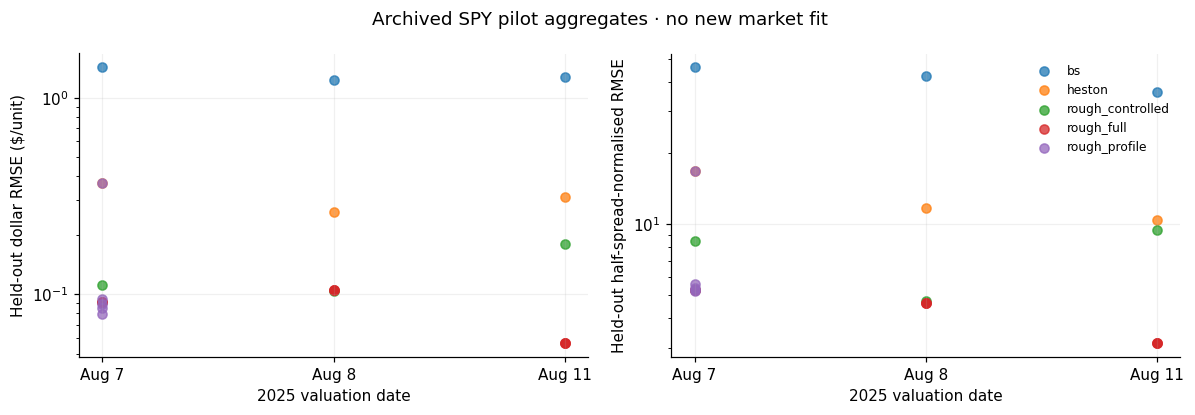

In [3]:
pilot = demo.aggregate("pilot_fit_attempts.csv")
market_attempts = pilot.loc[pilot.dataset.str.match(r"\d{4}-\d{2}-\d{2}")]
display(market_attempts.groupby(["dataset","model"], sort=False).agg(
    attempts=("status","size"), numerically_stable=("numerical_stable","sum"),
    market_fits_accepted=("market_fit_accepted","sum"),
    min_heldout_rmse=("heldout_dollar_rmse","min"), max_heldout_rmse=("heldout_dollar_rmse","max")))
figure = demo.pilot_figure()
display(figure)
plt.close(figure)

## 4. Refinement can rescue numerical checks without rescuing market fit

The later refinement extension repriced fixed fitted vectors; it did not refit or overwrite the coarse results. Five fixed-candidate terminal checks stabilized. The August 8 full-rough extension completed nine of ten pricing evaluations before a **partial timeout** interrupted its terminal 4,096-step call; its timeout array was never accepted. Three August 11 candidates were **unstarted when the campaign deadline arrived**. The original coarse fits remain unchanged. Stability of a repriced vector is different from acceptable errors relative to observed spreads. Neither the original results nor the extension supports an accepted model ranking.

In [4]:
display(demo.aggregate("pilot_refinement_outcomes.csv")[["date","model","display_status",
    "pricing_evaluations_completed","pricing_evaluations_attempted","terminal_refinement_stable"]])
display(demo.aggregate("pilot_refinement_summary.csv").groupby("date", sort=False).agg(
    comparisons=("check","size"), all_passed_comparisons=("all_checks_pass","sum")))

,date,model,display_status,pricing_evaluations_completed,pricing_evaluations_attempted,terminal_refinement_stable
0,2025-08-07,heston,complete,10,10,True
1,2025-08-07,rough_controlled,complete,10,10,True
2,2025-08-07,rough_full,complete,10,10,True
3,2025-08-08,heston,complete,10,10,True
4,2025-08-08,rough_controlled,complete,10,10,True
5,2025-08-08,rough_full,partial_timeout,9,10,False
6,2025-08-11,heston,unstarted_deadline,0,0,False
7,2025-08-11,rough_controlled,unstarted_deadline,0,0,False
8,2025-08-11,rough_full,unstarted_deadline,0,0,False


,comparisons,all_passed_comparisons
date,,
2025-08-07,42,37
2025-08-08,38,34


## 5. Reproduction and the next research step

The two synthetic notebooks execute against the current local Python source. This notebook executes a current **presence audit and verified aggregate display**, not a market-data reconstruction. The [aggregate manifest](../reports/aggregate_findings/manifest.json) records source content hashes and explicitly limits its provenance claim. Full source snapshots, licensed observations, detailed exclusions, sealed payloads and original audit logs remain local.

To repeat a real experiment, obtain the required licensed inputs, document their availability, run the explicit acquisition/preparation gates, then invoke the research campaign with a fresh output directory. Do not infer that a private pilot gate passes in a new environment. Future hedging also needs historical conditional state, validated target sensitivities, financing/cost conventions and a shared self-financing ledger.